In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

Saving superstore_sales.csv to superstore_sales.csv


In [3]:

# Load the Superstore dataset
df = pd.read_csv("superstore_sales.csv")

# Display the first five rows
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [4]:

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Statistical summary
display(df.describe(include="all").T)


Dataset shape: (10800, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   obj

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,10800,10001,Yes,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,10800,5015,CA-2018-100111,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1236,9/5/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2016,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

# Missing values by column
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_values.sort_values(
    by="Missing Count",
    ascending=False
))

# Check exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())


,Missing Count,Missing Percentage
Postal Code,817,7.56
Ship Mode,806,7.46
Ship Date,806,7.46
Customer ID,806,7.46
Order Date,806,7.46
Product ID,806,7.46
Category,806,7.46
Segment,806,7.46
Customer Name,806,7.46
Country,806,7.46


Duplicate rows: 504


In [6]:

# Keep rows belonging to the sales transactions table
sales_df = df[
    df["Order ID"].notna() &
    df["Order Date"].notna()
].copy()

# Convert dates using the dataset's month/day/year format
sales_df["Order Date"] = pd.to_datetime(
    sales_df["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

sales_df["Ship Date"] = pd.to_datetime(
    sales_df["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Create Year-Month for monthly analysis
sales_df["Year-Month"] = (
    sales_df["Order Date"].dt.to_period("M")
)

print("Cleaned sales records:", len(sales_df))
print("\nRemaining missing values:")
print(sales_df.isnull().sum())


Cleaned sales records: 9994

Remaining missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Year-Month        0
dtype: int64


In [7]:

# Check for duplicate records in the cleaned sales dataset

print("Total sales records:", len(sales_df))

print("Exact duplicate rows:", sales_df.duplicated().sum())

print("Duplicate Row IDs:", sales_df["Row ID"].duplicated().sum())

print("Unique orders:", sales_df["Order ID"].nunique())

print("Unique customers:", sales_df["Customer ID"].nunique())


Total sales records: 9994
Exact duplicate rows: 0
Duplicate Row IDs: 0
Unique orders: 5009
Unique customers: 793


In [8]:

# Inspect records with missing postal codes

missing_postal = sales_df[
    sales_df["Postal Code"].isna()
]

print("Records with missing postal codes:", len(missing_postal))

display(
    missing_postal[
        ["City", "State", "Region", "Postal Code", "Sales", "Profit"]
    ]
)


Records with missing postal codes: 11


,City,State,Region,Postal Code,Sales,Profit
2234,Burlington,Vermont,East,NaN,205.03,67.6599
5274,Burlington,Vermont,East,NaN,715.20,178.8000
8798,Burlington,Vermont,East,NaN,1294.75,336.6350
9146,Burlington,Vermont,East,NaN,99.98,42.9914
9147,Burlington,Vermont,East,NaN,8.04,2.7336
9148,Burlington,Vermont,East,NaN,1564.29,406.7154
9386,Burlington,Vermont,East,NaN,79.92,37.5624
9387,Burlington,Vermont,East,NaN,12.28,5.7716
9388,Burlington,Vermont,East,NaN,542.94,152.0232
9389,Burlington,Vermont,East,NaN,2.04,0.9588


In [9]:

# Convert postal codes to strings while preserving missing values
sales_df["Postal Code"] = sales_df["Postal Code"].astype("Int64").astype("string")

# Replace missing postal codes with "Unknown"
sales_df["Postal Code"] = sales_df["Postal Code"].fillna("Unknown")

# Verify that no missing values remain
print("Remaining missing values:")
print(sales_df.isnull().sum())

print("\nUpdated postal codes for Burlington, Vermont:")
display(
    sales_df.loc[
        (sales_df["City"] == "Burlington") &
        (sales_df["State"] == "Vermont"),
        ["City", "State", "Postal Code"]
    ].head()
)

Remaining missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year-Month       0
dtype: int64

Updated postal codes for Burlington, Vermont:


,City,State,Postal Code
2234,Burlington,Vermont,Unknown
5274,Burlington,Vermont,Unknown
8798,Burlington,Vermont,Unknown
9146,Burlington,Vermont,Unknown
9147,Burlington,Vermont,Unknown


In [10]:

# Step 9: Validate numerical columns

numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]

# Display summary statistics
print("Numerical Data Summary:")
display(sales_df[numeric_columns].describe())

# Check for invalid values
print("\nData Validation Results:")

print("Negative or zero sales:",
      (sales_df["Sales"] <= 0).sum())

print("Negative or zero quantities:",
      (sales_df["Quantity"] <= 0).sum())

print("Non-integer quantities:",
      (sales_df["Quantity"] % 1 != 0).sum())

print("Invalid discounts:",
      ((sales_df["Discount"] < 0) |
       (sales_df["Discount"] > 1)).sum())

print("Negative profit records:",
      (sales_df["Profit"] < 0).sum())

print("Zero profit records:",
      (sales_df["Profit"] == 0).sum())


Numerical Data Summary:


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000



Data Validation Results:
Negative or zero sales: 0
Negative or zero quantities: 0
Non-integer quantities: 0
Invalid discounts: 0
Negative profit records: 1871
Zero profit records: 65


In [11]:

# Step 10: Calculate overall business performance KPIs

total_sales = sales_df["Sales"].sum()
total_profit = sales_df["Profit"].sum()
total_orders = sales_df["Order ID"].nunique()
total_customers = sales_df["Customer ID"].nunique()
total_quantity = sales_df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

print("========== SUPERSTORE SALES PERFORMANCE ==========")

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Units Sold: {total_quantity:,.0f}")
print(f"Average Order Value: ${average_order_value:,.2f}")

print("==================================================")


========== SUPERSTORE SALES PERFORMANCE ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%
Total Orders: 5,009
Total Customers: 793
Total Units Sold: 37,873
Average Order Value: $458.61


In [12]:

# Step 11: Analyze sales and profit by product category

category_analysis = sales_df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin for each category
category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"]
) * 100

# Sort categories by total sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Format results for display
display(
    category_analysis.style.format({
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Total_Orders": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)


,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
2,Technology,"$836,154.03","$145,454.95","6,939","1,544",17.40%
0,Furniture,"$741,999.80","$18,451.27","8,028","1,764",2.49%
1,Office Supplies,"$719,047.03","$122,490.80","22,906","3,742",17.04%


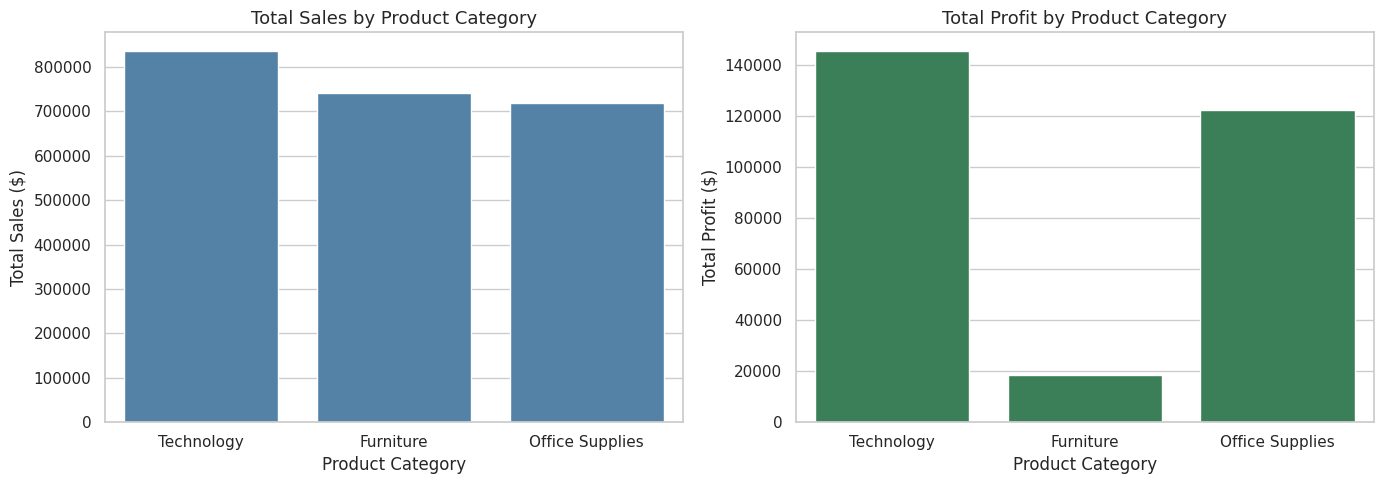

In [13]:

# Step 12: Visualize sales and profit by product category

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Total Sales by Category
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Total Sales by Product Category", fontsize=13)
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Total Sales ($)")

# Chart 2: Total Profit by Category
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Profit",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Total Profit by Product Category", fontsize=13)
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Total Profit ($)")

# Improve chart layout
plt.tight_layout()

# Save visualization for GitHub and final report
plt.savefig(
    "category_sales_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

# Step 13: Analyze sales and profit by region

region_analysis = sales_df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin by region
region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"]
) * 100

# Sort regions by total sales
region_analysis = region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Display formatted results
display(
    region_analysis.style.format({
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Total_Orders": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)


,Region,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
3,West,"$725,457.82","$108,418.45","12,266","1,611",14.94%
1,East,"$678,781.24","$91,522.78","10,618","1,401",13.48%
0,Central,"$501,239.89","$39,706.36","8,780","1,175",7.92%
2,South,"$391,721.91","$46,749.43","6,209",822,11.93%


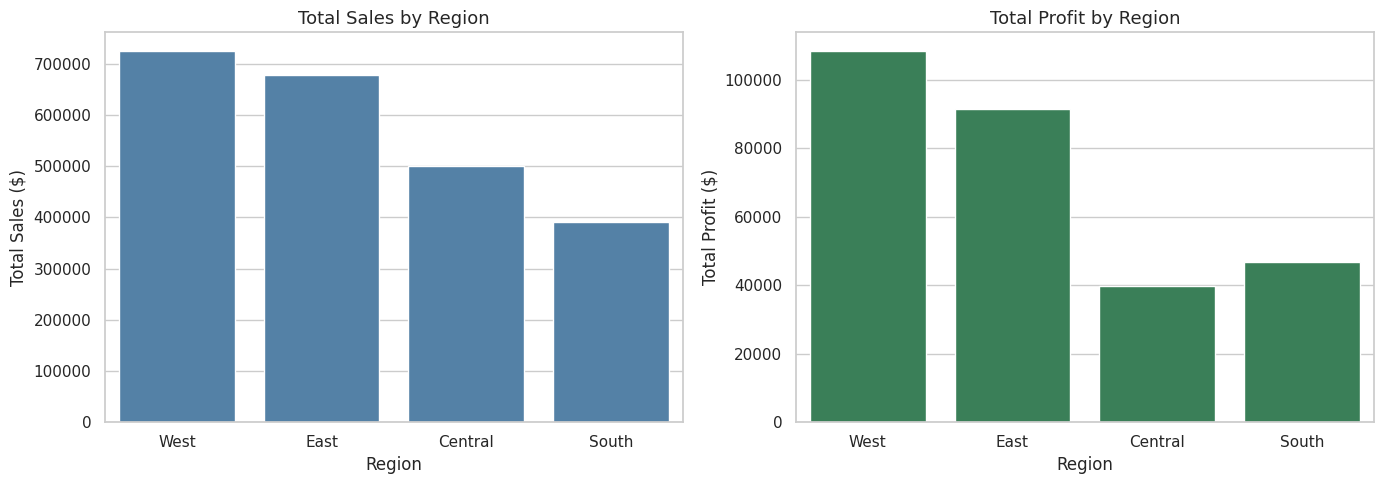

In [15]:

# Step 14: Visualize sales and profit by region

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Total Sales by Region
sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Total Sales by Region", fontsize=13)
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Total Sales ($)")

# Chart 2: Total Profit by Region
sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Profit",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Total Profit by Region", fontsize=13)
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Total Profit ($)")

# Improve chart layout
plt.tight_layout()

# Save visualization
plt.savefig(
    "regional_sales_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [16]:

# Step 15: Analyze sales and profit by customer segment

segment_analysis = sales_df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Customers=("Customer ID", "nunique")
).reset_index()

# Calculate profit margin by segment
segment_analysis["Profit_Margin_%"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"]
) * 100

# Calculate average order value
segment_analysis["Average_Order_Value"] = (
    segment_analysis["Total_Sales"] /
    segment_analysis["Total_Orders"]
)

# Sort segments by total sales
segment_analysis = segment_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Display formatted results
display(
    segment_analysis.style.format({
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Total_Orders": "{:,.0f}",
        "Total_Customers": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Average_Order_Value": "${:,.2f}"
    })
)


,Segment,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Total_Customers,Profit_Margin_%,Average_Order_Value
0,Consumer,"$1,161,401.34","$134,119.21","19,521","2,586",409,11.55%,$449.11
1,Corporate,"$706,146.37","$91,979.13","11,608","1,514",236,13.03%,$466.41
2,Home Office,"$429,653.15","$60,298.68","6,744",909,148,14.03%,$472.67


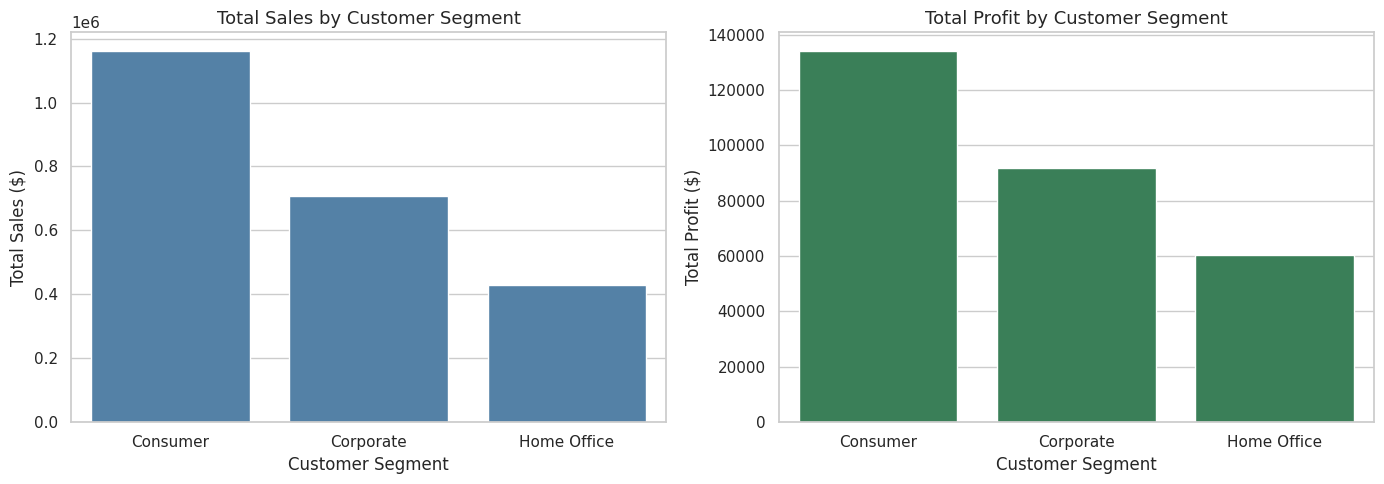

In [17]:

# Step 16: Visualize sales and profit by customer segment

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Total Sales by Customer Segment
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Sales",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Total Sales by Customer Segment", fontsize=13)
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Total Sales ($)")

# Chart 2: Total Profit by Customer Segment
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Profit",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Total Profit by Customer Segment", fontsize=13)
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Total Profit ($)")

# Improve layout
plt.tight_layout()

# Save visualization
plt.savefig(
    "customer_segment_sales_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [18]:

# Step 17: Analyze monthly sales and profit trends

# Extract year and month from Order Date
sales_df["Year"] = sales_df["Order Date"].dt.year
sales_df["Month"] = sales_df["Order Date"].dt.month

# Group sales and profit by year and month
monthly_analysis = sales_df.groupby(
    ["Year", "Month"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Create a monthly date column for visualization
monthly_analysis["Year_Month"] = pd.to_datetime(
    monthly_analysis[["Year", "Month"]].assign(DAY=1)
)

# Sort chronologically
monthly_analysis = monthly_analysis.sort_values(
    by="Year_Month"
)

# Display monthly results
display(
    monthly_analysis.style.format({
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Total_Orders": "{:,.0f}",
        "Year_Month": "{:%Y-%m}"
    })
)


,Year,Month,Total_Sales,Total_Profit,Total_Orders,Year_Month
0,2015,1,"$14,236.90","$2,450.19",32,2015-01
1,2015,2,"$4,519.89",$862.31,28,2015-02
2,2015,3,"$55,691.01",$498.73,71,2015-03
3,2015,4,"$28,295.35","$3,488.84",66,2015-04
4,2015,5,"$23,648.29","$2,738.71",69,2015-05
5,2015,6,"$34,595.13","$4,976.52",66,2015-06
6,2015,7,"$33,946.39",$-841.48,65,2015-07
7,2015,8,"$27,909.47","$5,318.10",72,2015-08
8,2015,9,"$81,777.35","$8,328.10",130,2015-09
9,2015,10,"$31,453.39","$3,448.26",78,2015-10


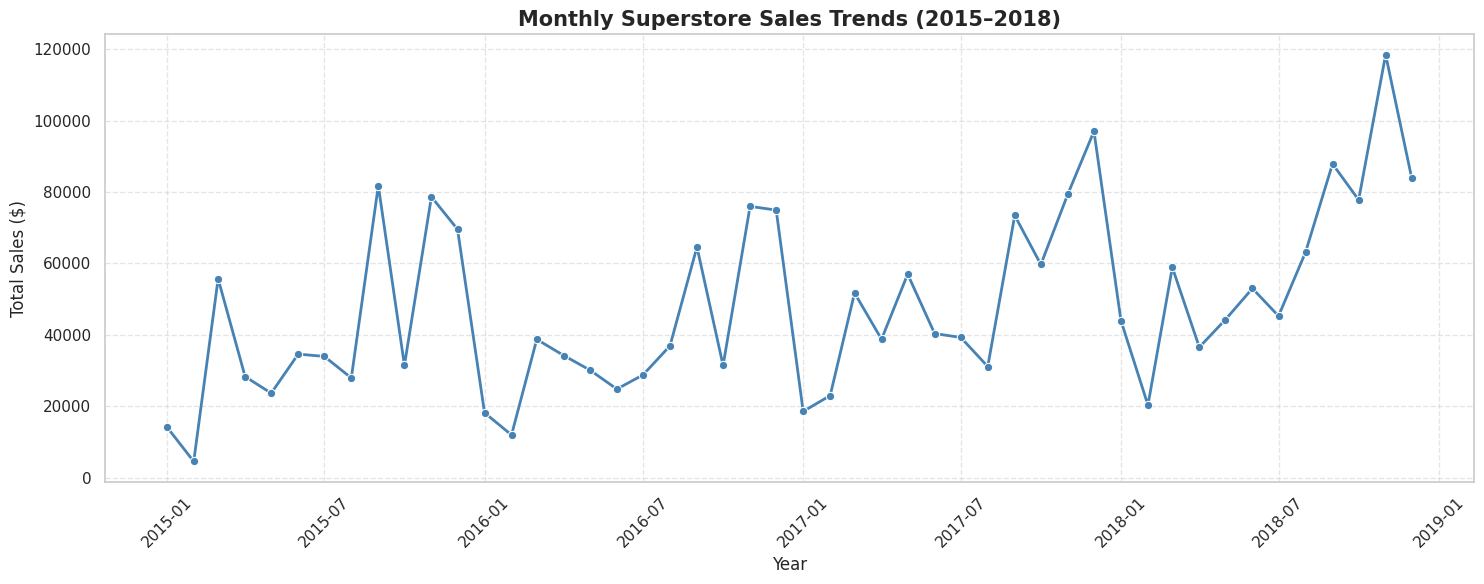

In [19]:

# Step 18: Visualize monthly sales trends

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_analysis,
    x="Year_Month",
    y="Total_Sales",
    marker="o",
    color="steelblue",
    linewidth=2
)

# Add chart title and axis labels
plt.title(
    "Monthly Superstore Sales Trends (2015–2018)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Total Sales ($)")

# Improve readability
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Save chart
plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


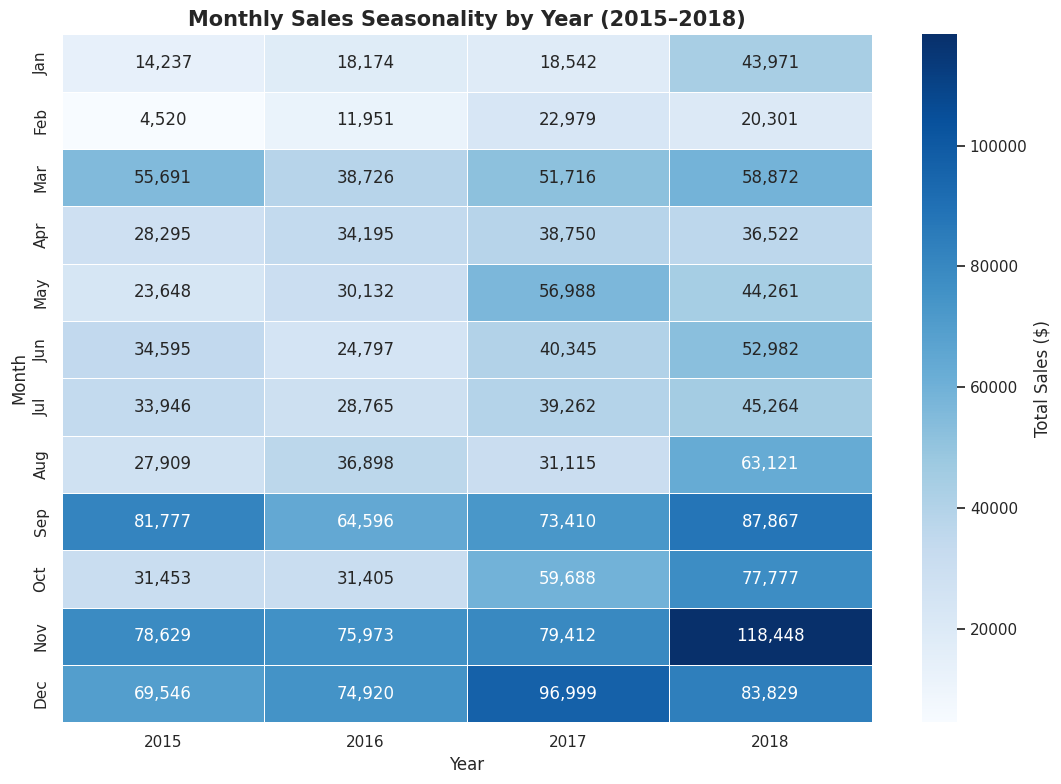

In [20]:

# Step 19: Analyze monthly sales seasonality using a heatmap

# Create a pivot table of monthly sales by year
seasonality_data = monthly_analysis.pivot(
    index="Month",
    columns="Year",
    values="Total_Sales"
)

# Replace month numbers with month names
seasonality_data.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Create heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    seasonality_data,
    annot=True,
    fmt=",.0f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Total Sales ($)"}
)

plt.title(
    "Monthly Sales Seasonality by Year (2015–2018)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()

# Save visualization
plt.savefig(
    "monthly_sales_seasonality_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [21]:

# Step 20: Calculate average monthly sales across all years

average_monthly_sales = monthly_analysis.groupby("Month").agg(
    Average_Sales=("Total_Sales", "mean"),
    Average_Profit=("Total_Profit", "mean"),
    Average_Orders=("Total_Orders", "mean")
).reset_index()

# Add month names
average_monthly_sales["Month_Name"] = pd.to_datetime(
    average_monthly_sales["Month"],
    format="%m"
).dt.strftime("%B")

# Display formatted results
display(
    average_monthly_sales[
        ["Month_Name", "Average_Sales",
         "Average_Profit", "Average_Orders"]
    ].style.format({
        "Average_Sales": "${:,.2f}",
        "Average_Profit": "${:,.2f}",
        "Average_Orders": "{:.1f}"
    })
)


,Month_Name,Average_Sales,Average_Profit,Average_Orders
0,January,"$23,731.21","$2,283.61",44.5
1,February,"$14,937.81","$2,573.65",40.5
2,March,"$51,251.37","$7,148.67",88.5
3,April,"$34,440.53","$2,896.86",85.8
4,May,"$38,757.20","$5,602.83",92.2
5,June,"$38,179.67","$5,321.45",91.0
6,July,"$36,809.52","$3,458.17",84.5
7,August,"$39,761.02","$5,444.23",85.2
8,September,"$76,912.49","$9,214.37",172.0
9,October,"$50,080.75","$7,946.01",104.2


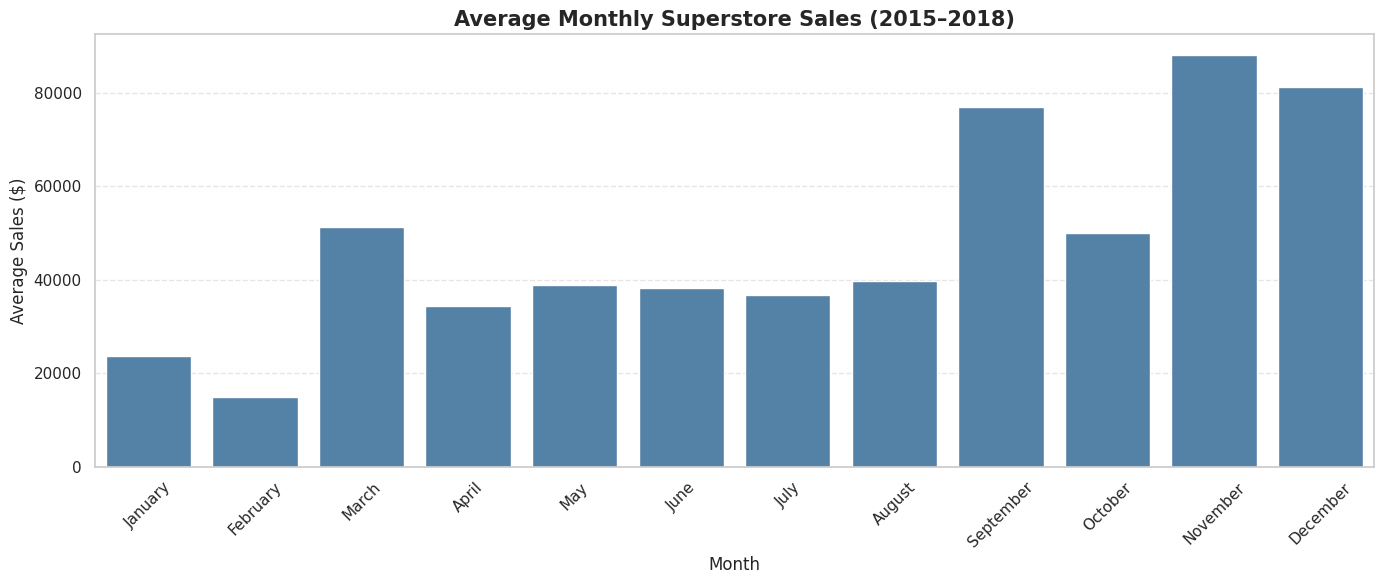

In [22]:

# Step 21: Visualize average monthly sales

plt.figure(figsize=(14, 6))

sns.barplot(
    data=average_monthly_sales,
    x="Month_Name",
    y="Average_Sales",
    color="steelblue"
)

# Add chart title and labels
plt.title(
    "Average Monthly Superstore Sales (2015–2018)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Sales ($)")

# Improve readability
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save visualization
plt.savefig(
    "average_monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


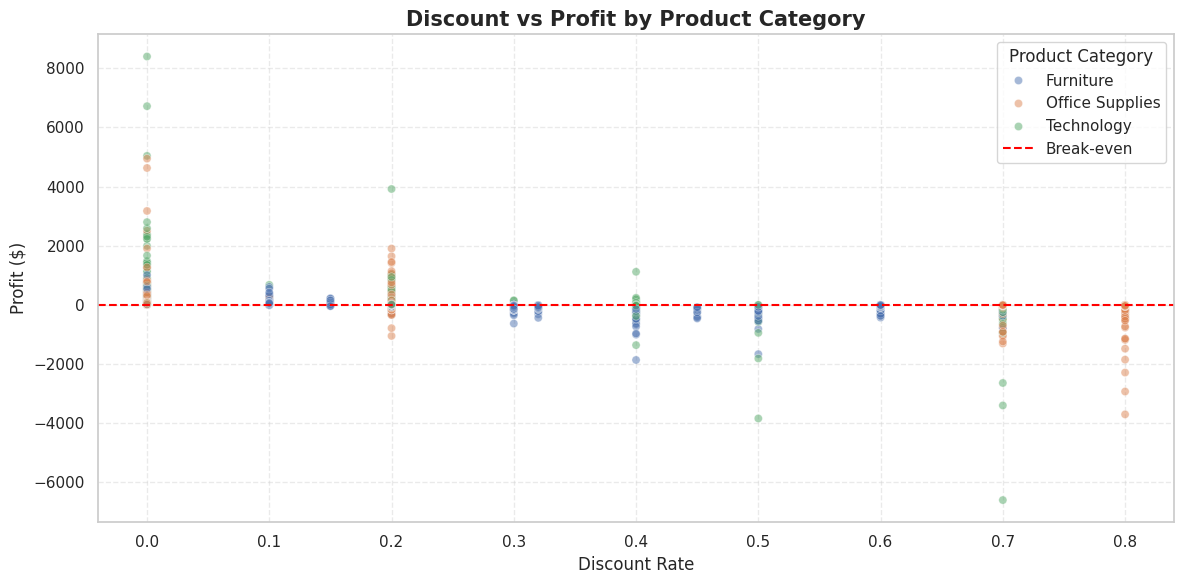

In [23]:

# Step 22: Analyze the relationship between discounts and profit

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=sales_df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.5,
    s=35
)

# Add a horizontal reference line at zero profit
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Break-even"
)

plt.title(
    "Discount vs Profit by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Discount Rate")
plt.ylabel("Profit ($)")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Product Category")

plt.tight_layout()

# Save visualization
plt.savefig(
    "discount_vs_profit_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [24]:

# Step 23: Analyze profitability by discount level

discount_analysis = sales_df.groupby("Discount").agg(
    Total_Transactions=("Profit", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Loss_Transactions=("Profit", lambda x: (x < 0).sum())
).reset_index()

# Calculate profit margin
discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"]
) * 100

# Calculate percentage of loss-making transactions
discount_analysis["Loss_Rate_%"] = (
    discount_analysis["Loss_Transactions"] /
    discount_analysis["Total_Transactions"]
) * 100

# Convert discount to percentage for display
discount_analysis["Discount_%"] = (
    discount_analysis["Discount"] * 100
)

# Display results
display(
    discount_analysis[
        [
            "Discount_%",
            "Total_Transactions",
            "Total_Sales",
            "Total_Profit",
            "Average_Profit",
            "Profit_Margin_%",
            "Loss_Rate_%"
        ]
    ].style.format({
        "Discount_%": "{:.0f}%",
        "Total_Transactions": "{:,.0f}",
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Average_Profit": "${:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "Loss_Rate_%": "{:.2f}%"
    })
)


,Discount_%,Total_Transactions,Total_Sales,Total_Profit,Average_Profit,Profit_Margin_%,Loss_Rate_%
0,0%,"4,798","$1,087,908.47","$320,987.60",$66.90,29.51%,0.00%
1,10%,94,"$54,369.35","$9,029.18",$96.06,16.61%,4.26%
2,15%,52,"$27,558.52","$1,418.99",$27.29,5.15%,32.69%
3,20%,"3,657","$764,594.37","$90,337.31",$24.70,11.82%,13.73%
4,30%,227,"$103,226.65","$-10,369.28",$-45.68,-10.05%,91.63%
5,32%,27,"$14,493.46","$-2,391.14",$-88.56,-16.50%,100.00%
6,40%,206,"$116,417.78","$-23,057.05",$-111.93,-19.81%,87.38%
7,45%,11,"$5,484.97","$-2,493.11",$-226.65,-45.45%,100.00%
8,50%,66,"$58,918.54","$-20,506.43",$-310.70,-34.80%,100.00%
9,60%,138,"$6,644.70","$-5,944.66",$-43.08,-89.46%,100.00%


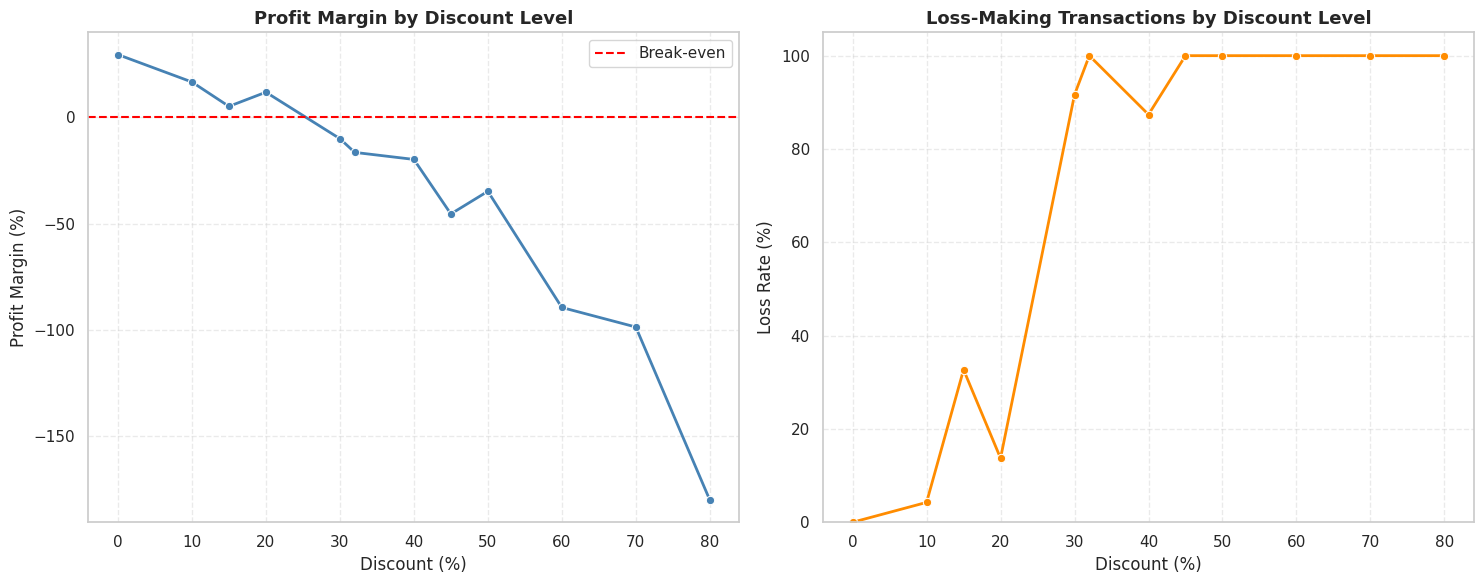

In [25]:

# Step 24: Visualize profitability and loss rate by discount level

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Profit Margin by Discount Level
sns.lineplot(
    data=discount_analysis,
    x="Discount_%",
    y="Profit_Margin_%",
    marker="o",
    color="steelblue",
    linewidth=2,
    ax=axes[0]
)

axes[0].axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Break-even"
)

axes[0].set_title(
    "Profit Margin by Discount Level",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Discount (%)")
axes[0].set_ylabel("Profit Margin (%)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Chart 2: Loss Rate by Discount Level
sns.lineplot(
    data=discount_analysis,
    x="Discount_%",
    y="Loss_Rate_%",
    marker="o",
    color="darkorange",
    linewidth=2,
    ax=axes[1]
)

axes[1].set_title(
    "Loss-Making Transactions by Discount Level",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Discount (%)")
axes[1].set_ylabel("Loss Rate (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

# Save visualization
plt.savefig(
    "discount_profitability_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [26]:

# Step 25: Analyze sales and profitability by product subcategory

subcategory_analysis = sales_df.groupby(
    ["Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
).reset_index()

# Calculate profit margin
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"] /
    subcategory_analysis["Total_Sales"]
) * 100

# Convert average discount to percentage
subcategory_analysis["Average_Discount_%"] = (
    subcategory_analysis["Average_Discount"] * 100
)

# Sort by total profit, highest to lowest
subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

# Display formatted results
display(
    subcategory_analysis[
        [
            "Category",
            "Sub-Category",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Profit_Margin_%",
            "Average_Discount_%"
        ]
    ].style.format({
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Average_Discount_%": "{:.2f}%"
    })
)


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%,Average_Discount_%
14,Technology,Copiers,"$149,528.03","$55,617.82",234,37.20%,16.18%
16,Technology,Phones,"$330,007.05","$44,515.73","3,289",13.49%,15.46%
13,Technology,Accessories,"$167,380.32","$41,936.64","2,976",25.05%,7.85%
10,Office Supplies,Paper,"$78,479.21","$34,053.57","5,178",43.39%,7.49%
6,Office Supplies,Binders,"$203,412.73","$30,221.76","5,974",14.86%,37.23%
1,Furniture,Chairs,"$328,449.10","$26,590.17","2,356",8.10%,17.02%
11,Office Supplies,Storage,"$223,843.61","$21,278.83","3,158",9.51%,7.47%
4,Office Supplies,Appliances,"$107,532.16","$18,138.01","1,729",16.87%,16.65%
2,Furniture,Furnishings,"$91,705.16","$13,059.14","3,563",14.24%,13.83%
7,Office Supplies,Envelopes,"$16,476.40","$6,964.18",906,42.27%,8.03%


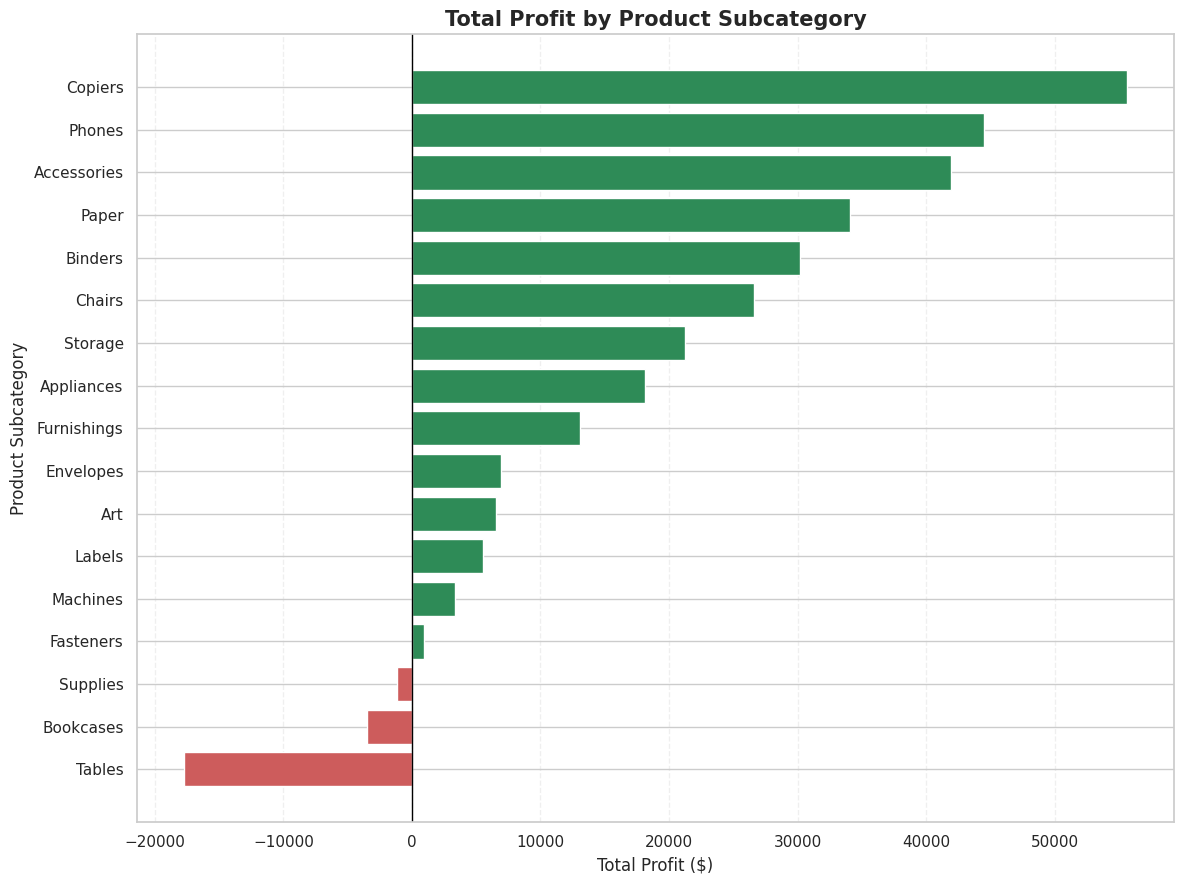

In [27]:

# Step 26: Visualize total profit by product subcategory

# Sort subcategories by total profit
subcategory_plot = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

# Assign colors based on profitability
colors = [
    "seagreen" if profit >= 0 else "indianred"
    for profit in subcategory_plot["Total_Profit"]
]

plt.figure(figsize=(12, 9))

# Create horizontal bar chart
plt.barh(
    subcategory_plot["Sub-Category"],
    subcategory_plot["Total_Profit"],
    color=colors
)

# Add zero-profit reference line
plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.title(
    "Total Profit by Product Subcategory",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Profit ($)")
plt.ylabel("Product Subcategory")

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# Save visualization
plt.savefig(
    "subcategory_profitability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

# Step 27: Analyze customer purchase volume

customer_analysis = sales_df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate average order value per customer
customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Sales"] /
    customer_analysis["Total_Orders"]
)

# Sort customers by total sales
customer_analysis = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Display the top 10 customers
print("Top 10 Customers by Total Sales:")

display(
    customer_analysis.head(10).style.format({
        "Total_Orders": "{:,.0f}",
        "Total_Sales": "${:,.2f}",
        "Total_Profit": "${:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Average_Order_Value": "${:,.2f}"
    })
)


Top 10 Customers by Total Sales:


,Customer ID,Customer Name,Total_Orders,Total_Sales,Total_Profit,Total_Quantity,Average_Order_Value
700,SM-20320,Sean Miller,5,"$25,043.05","$-1,980.74",50,"$5,008.61"
741,TC-20980,Tamara Chand,5,"$19,052.22","$8,981.32",42,"$3,810.44"
621,RB-19360,Raymond Buch,6,"$15,117.34","$6,976.10",71,"$2,519.56"
730,TA-21385,Tom Ashbrook,4,"$14,595.62","$4,703.79",36,"$3,648.91"
6,AB-10105,Adrian Barton,10,"$14,473.57","$5,444.81",73,"$1,447.36"
434,KL-16645,Ken Lonsdale,12,"$14,175.23",$806.86,113,"$1,181.27"
669,SC-20095,Sanjit Chand,9,"$14,142.33","$5,757.41",87,"$1,571.37"
327,HL-15040,Hunter Lopez,6,"$12,873.30","$5,622.43",50,"$2,145.55"
683,SE-20110,Sanjit Engle,11,"$12,209.44","$2,650.68",78,"$1,109.95"
131,CC-12370,Christopher Conant,5,"$12,129.07","$2,177.05",34,"$2,425.81"


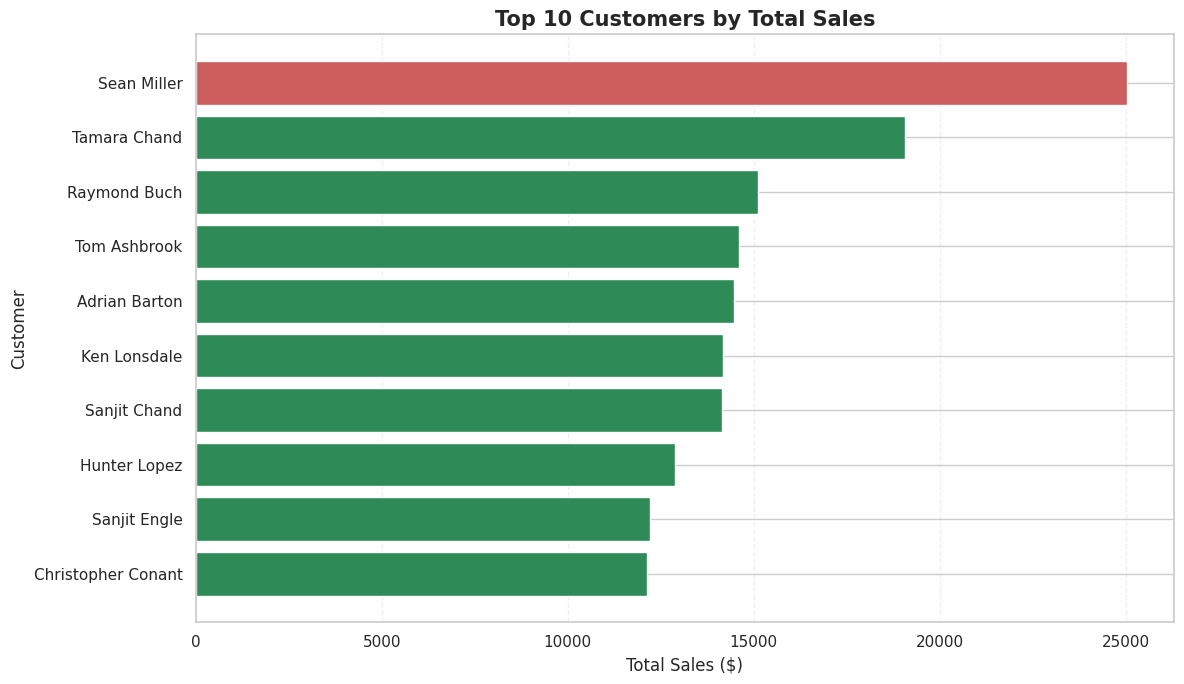

In [29]:

# Step 28: Visualize top 10 customers by total sales

# Select the top 10 customers
top_customers = customer_analysis.head(10).copy()

# Sort by total sales for horizontal visualization
top_customers = top_customers.sort_values(
    by="Total_Sales",
    ascending=True
)

# Assign colors based on customer profitability
colors = [
    "seagreen" if profit >= 0 else "indianred"
    for profit in top_customers["Total_Profit"]
]

plt.figure(figsize=(12, 7))

# Create horizontal bar chart
plt.barh(
    top_customers["Customer Name"],
    top_customers["Total_Sales"],
    color=colors
)

plt.title(
    "Top 10 Customers by Total Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Sales ($)")
plt.ylabel("Customer")

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# Save visualization
plt.savefig(
    "top_10_customers_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [30]:

# Step 29: Analyze customer purchase frequency

# Calculate the distribution of orders per customer
purchase_frequency = (
    customer_analysis["Total_Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

purchase_frequency.columns = [
    "Number_of_Orders",
    "Number_of_Customers"
]

# Calculate percentage of customers
purchase_frequency["Customer_Percentage"] = (
    purchase_frequency["Number_of_Customers"] /
    len(customer_analysis)
) * 100

# Display purchase frequency distribution
print("Customer Purchase Frequency Distribution:")

display(
    purchase_frequency.style.format({
        "Number_of_Orders": "{:,.0f}",
        "Number_of_Customers": "{:,.0f}",
        "Customer_Percentage": "{:.2f}%"
    })
)

# Calculate summary statistics
print("\nCustomer Purchase Frequency Summary:")

print(
    "Average orders per customer:",
    round(customer_analysis["Total_Orders"].mean(), 2)
)

print(
    "Median orders per customer:",
    customer_analysis["Total_Orders"].median()
)

print(
    "Maximum orders by a customer:",
    customer_analysis["Total_Orders"].max()
)


Customer Purchase Frequency Distribution:


,Number_of_Orders,Number_of_Customers,Customer_Percentage
0,1,12,1.51%
1,2,34,4.29%
2,3,53,6.68%
3,4,96,12.11%
4,5,134,16.90%
5,6,107,13.49%
6,7,116,14.63%
7,8,82,10.34%
8,9,71,8.95%
9,10,39,4.92%



Customer Purchase Frequency Summary:
Average orders per customer: 6.32
Median orders per customer: 6.0
Maximum orders by a customer: 17


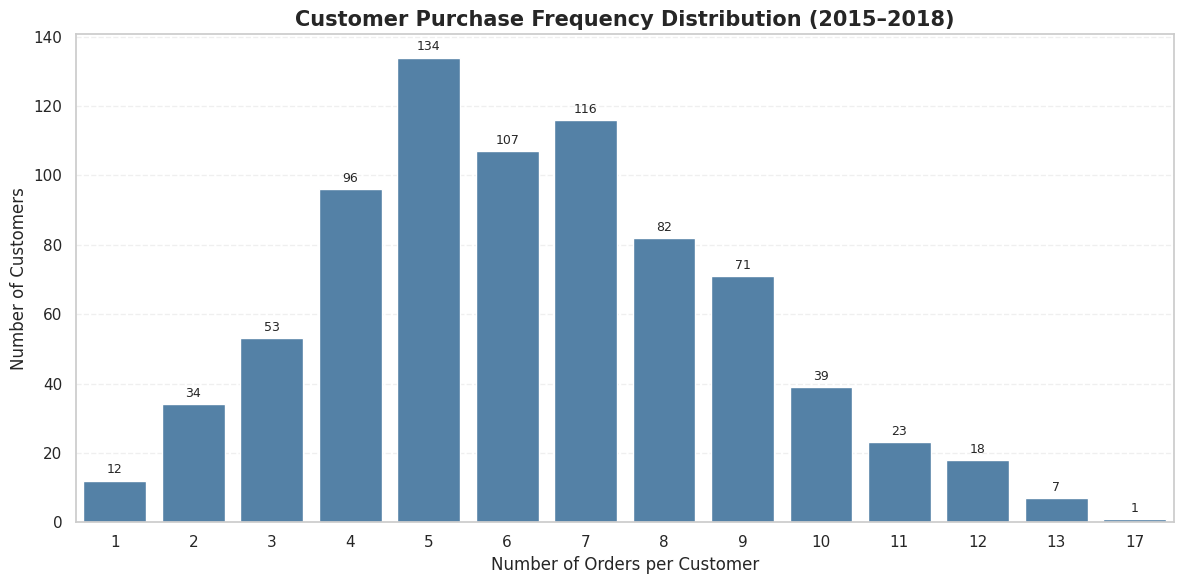

In [31]:

# Step 30: Visualize customer purchase frequency

plt.figure(figsize=(12, 6))

sns.barplot(
    data=purchase_frequency,
    x="Number_of_Orders",
    y="Number_of_Customers",
    color="steelblue"
)

plt.title(
    "Customer Purchase Frequency Distribution (2015–2018)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Orders per Customer")
plt.ylabel("Number of Customers")

# Add customer counts above each bar
ax = plt.gca()

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=9
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# Save visualization
plt.savefig(
    "customer_purchase_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [32]:

# Step 31: Validate final EDA calculations

print("========== FINAL EDA VALIDATION ==========")

# Validate sales totals
print("\nSales Validation:")
print("Dataset Total Sales:", round(sales_df["Sales"].sum(), 2))
print("Category Total Sales:", round(category_analysis["Total_Sales"].sum(), 2))
print("Region Total Sales:", round(region_analysis["Total_Sales"].sum(), 2))
print("Segment Total Sales:", round(segment_analysis["Total_Sales"].sum(), 2))
print("Monthly Total Sales:", round(monthly_analysis["Total_Sales"].sum(), 2))

# Validate profit totals
print("\nProfit Validation:")
print("Dataset Total Profit:", round(sales_df["Profit"].sum(), 2))
print("Category Total Profit:", round(category_analysis["Total_Profit"].sum(), 2))
print("Region Total Profit:", round(region_analysis["Total_Profit"].sum(), 2))
print("Segment Total Profit:", round(segment_analysis["Total_Profit"].sum(), 2))

# Validate customer counts
print("\nCustomer Validation:")
print("Unique Customers:", sales_df["Customer ID"].nunique())
print("Customers Analyzed:", len(customer_analysis))
print("Purchase Frequency Total:", purchase_frequency["Number_of_Customers"].sum())

# Check missing values and duplicates
print("\nData Quality:")
print("Missing Values:", sales_df.isnull().sum().sum())
print("Duplicate Rows:", sales_df.duplicated().sum())

# Automated consistency checks
assert np.isclose(
    sales_df["Sales"].sum(),
    category_analysis["Total_Sales"].sum()
)

assert np.isclose(
    sales_df["Profit"].sum(),
    region_analysis["Total_Profit"].sum()
)

assert sales_df["Customer ID"].nunique() == len(customer_analysis)

print("\nAll validation checks passed!")


========== FINAL EDA VALIDATION ==========

Sales Validation:
Dataset Total Sales: 2297200.86
Category Total Sales: 2297200.86
Region Total Sales: 2297200.86
Segment Total Sales: 2297200.86
Monthly Total Sales: 2297200.86

Profit Validation:
Dataset Total Profit: 286397.02
Category Total Profit: 286397.02
Region Total Profit: 286397.02
Segment Total Profit: 286397.02

Customer Validation:
Unique Customers: 793
Customers Analyzed: 793
Purchase Frequency Total: 793

Data Quality:
Missing Values: 0
Duplicate Rows: 0

All validation checks passed!


# Executive Business Findings and Recommendations

## Superstore Retail Sales Exploratory Data Analysis (2015–2018)

### Business Performance Overview

The Superstore dataset contains 9,994 cleaned sales records covering 5,009 unique orders and 793 customers between 2015 and 2018.

The business generated **$2,297,200.86 in total sales** and **$286,397.02 in total profit**, achieving an overall profit margin of **12.47%**.

The following findings summarize the most important business insights identified through exploratory data analysis.

### Finding 1: Technology Is the Most Profitable Product Category

Technology generated **$836,154.03 in sales** and **$145,454.95 in profit**, achieving a profit margin of 17.40%.

Furniture generated $741,999.80 in sales but only $18,451.27 in profit, resulting in a considerably lower margin of 2.49%.

**Recommendation:** Prioritize the profitability of Technology products while investigating pricing, discounting, and cost structures within Furniture.

### Finding 2: The West Region Leads in Sales and Profitability

The West region generated **$725,457.82 in sales** and **$108,418.45 in profit**, with a profit margin of 14.94%.

The Central region recorded the lowest profit margin at 7.92%.

**Recommendation:** Investigate the factors associated with the West region's stronger performance and identify opportunities to improve profitability in the Central region.

### Finding 3: Consumer Customers Generate the Highest Revenue

The Consumer segment generated **$1,161,401.34 in sales** and **$134,119.21 in profit**, making it the largest customer segment by revenue.

However, the Home Office segment achieved the highest profit margin at 14.03%, compared with 11.55% for Consumer customers.

**Recommendation:** Maintain engagement with Consumer customers while exploring profitable growth opportunities within the Home Office segment.

### Finding 4: Sales Show Strong Seasonal Patterns

Sales activity increased noticeably during September, November, and December.

November recorded the highest average monthly sales at **$88,115.27**, followed by December at $81,323.38 and September at $76,912.49.

February recorded the lowest average monthly sales at $14,937.81.

**Recommendation:** Use historical seasonal patterns to inform inventory planning, staffing, and marketing activities, particularly during high-demand months.

### Finding 5: High Discounts Are Associated With Financial Losses

Transactions without discounts achieved a profit margin of **29.51%**.

At a 20% discount, the aggregate profit margin remained positive at 11.82%. However, at a 30% discount, the margin declined to -10.05%.

Discount levels of 50% and above were associated with losses across all recorded sales lines at those levels.

**Recommendation:** Review discount policies, especially for discounts of 30% or higher. Assess product costs and profitability before approving substantial discounts.

These findings demonstrate an association between discount levels and profitability, not a proven causal relationship.

### Finding 6: Tables and Bookcases Reduce Furniture Profitability

Tables generated **$17,725.48 in losses**, making them the least profitable product subcategory.

Bookcases also recorded losses of $3,472.56.

In contrast, Copiers generated the highest total profit among all subcategories at $55,617.82.

**Recommendation:** Review the pricing, discounts, and costs associated with Tables and Bookcases. Evaluate opportunities to strengthen profitable product lines.

### Finding 7: High Customer Revenue Does Not Always Mean High Profit

Sean Miller generated the highest individual customer revenue at **$25,043.05**, but his purchases resulted in a net loss of $1,980.74.

In comparison, Tamara Chand generated $19,052.22 in sales and $8,981.32 in profit.

**Recommendation:** Evaluate customers using both revenue and profitability rather than relying exclusively on total spending.

### Finding 8: Repeat Purchasing Is Common Among Customers

Across the four-year period, customers placed an average of **6.32 orders**, with a median of 6 orders.

Approximately **98.49% of customers** placed more than one order, while only 1.51% placed a single order.

**Recommendation:** Investigate repeat purchasing patterns further and consider customer engagement strategies based on purchase frequency and profitability.

This analysis measures repeat purchasing within the dataset and does not establish formal customer retention rates.

---

## Overall Business Recommendations

Based on the analysis, the business should focus on improving product profitability, reviewing high-discount transactions, addressing underperforming subcategories, and using seasonal demand patterns to support operational planning.

Customer profitability and purchase frequency should also be considered when developing sales and customer engagement strategies.

These recommendations are based on historical descriptive analysis and should be evaluated further before implementation.

## Conclusion

The exploratory data analysis identified meaningful differences in sales performance, profitability, purchasing behavior, and discount sensitivity across the Superstore business.

Although the business generated more than $2.29 million in sales, profitability varied substantially across categories, regions, products, and customers.

The findings demonstrate how data analysis can support business decision-making by identifying performance strengths, financial risks, and opportunities for further investigation.